# 📘 Notebook 06: Wine Quality, Can Chemistry Predict Taste?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 6 · Portuguese Vinho Verde wines (6,497 wines, 12 measurements and a score)*

---

> 💡 **This notebook is already run.** Every table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything. To experiment, choose **Runtime → Run all** in Colab; the whole notebook runs in about a minute. If you rerun it, numbers from the models may differ slightly in the last decimal, because Colab may have newer library versions.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- **Combine** two related files into one dataset without losing track of where each row came from
- Find **duplicate rows** and measure how much they **inflate** a model's score
- Explore a target that is a **score**: ordered, narrow and concentrated in the middle
- See why models **pull predictions towards the average** on such targets
- Decide whether to treat a score as a **number** or as **classes**

> **Prerequisites:** [Notebook 03: House Prices](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-questions-to-answers/03_house_prices.ipynb) for regression and the mean absolute error.
>
> 🔭 **Why this notebook matters:** many targets in practice are **scores given by people**: a star rating, a satisfaction survey, an exam grade, a tasting panel. They look like numbers, but most values sit in the middle, the extremes are rare, and the people giving them disagree. This dataset, collected by Paulo Cortez and colleagues for the Vinho Verde region of Portugal, shows all of these problems at once, and adds a classic data trap: rows that appear more than once.

## 0. The question

For each wine, a laboratory measured eleven chemical properties (acidity, sugar, sulphur, alcohol...) and at least three expert tasters gave a score from 0 (very bad) to 10 (excellent). The score is the median of their grades.

**Our question:** *Can chemistry predict how good a wine tastes?* More precisely:

1. Which chemical properties go with better scores, for red and for white wine?
2. How well can a model predict the score, and where does it fail?
3. Can we at least pick out the **good** wines?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

## 1. Loading two files and combining them

The data comes as **two files**, one for red and one for white wine, from the UCI repository. They are separated by semicolons, so we use `sep=";"`. Before stacking them into one table, we add a column that records which file each row came from; otherwise that information would be lost for ever.

In [2]:
BASE = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
red = pd.read_csv(BASE + "winequality-red.csv", sep=";")
white = pd.read_csv(BASE + "winequality-white.csv", sep=";")
print("red:", red.shape, " white:", white.shape)
red["type"] = "red"
white["type"] = "white"
df = pd.concat([red, white], ignore_index=True)
print("combined:", df.shape)
df.head()

red: (1599, 12)  white: (4898, 12)
combined: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,red


**What we see.** 1,599 red and 4,898 white wines, 6,497 in total, each with 11 measurements, the `quality` score and the `type` we added. All measurements are numbers and none are missing, which makes this the cleanest dataset of the course so far. Clean, however, does not mean trouble-free.

## 2. Duplicates: a trap with a measurable cost

In [3]:
print("Duplicate rows, red:  ", red.duplicated().sum())
print("Duplicate rows, white:", white.duplicated().sum())
print("Duplicate rows, all:  ", df.duplicated().sum(), "of", len(df))

Duplicate rows, red:   240
Duplicate rows, white: 937
Duplicate rows, all:   1177 of 6497


**What we see.** **1,177** rows, **18%** of the data, are exact copies of another row: 240 red and 937 white. Two different wines could in principle have identical measurements to two decimals, but this many identical rows almost certainly means the same samples were entered more than once.

Why does it matter? When the data is split for cross-validation, a wine can land in the **training** part and its copy in the **test** part. The model is then "tested" on a wine it has already seen, and its score looks better than it really is. This is a form of **data leakage**. We do not have to guess how large the effect is; we can measure it (Section 5). For the exploration, we drop the copies.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print(len(df), "unique wines")

5320 unique wines


## 3. The target: a score, not a measurement

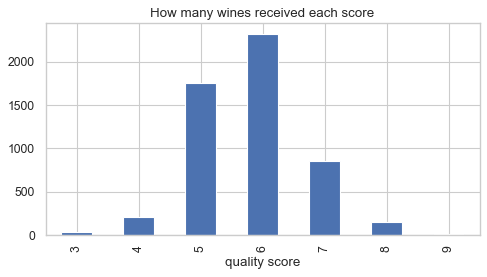

           3    4     5     6     7    8    9
percent  0.6  3.9  32.9  43.7  16.1  2.8  0.1


In [5]:
counts = df["quality"].value_counts().sort_index()
plt.figure(figsize=(7, 3.5))
counts.plot.bar()
plt.title("How many wines received each score")
plt.xlabel("quality score")
plt.show()
print((100 * counts / counts.sum()).round(1).to_frame("percent").T)

**What we see.** The scale runs from 0 to 10, but only **3 to 9** were ever used, and most wines got a **5 or a 6** (about three quarters together). Scores of 3, 8 and 9 are rare; there are only a handful of 9s. This is typical of human ratings: tasters avoid the extremes, and most products really are average.

Two consequences for everything that follows: a model that always says "6" will be close most of the time, and it will be very hard to learn what makes a 3 or a 9 from so few examples.

In [6]:
df.groupby("type")["quality"].agg(["mean", "median", "size"]).round(2)

,mean,median,size
type,,,
red,5.62,6.0,1359
white,5.85,6.0,3961


**What we see.** White wines score slightly higher on average (**5.85** against **5.62**), with the same median of 6. The difference is small, but red and white wines are chemically different drinks, so we will check whether the same properties matter for both.

## 4. Which chemistry goes with a better score?

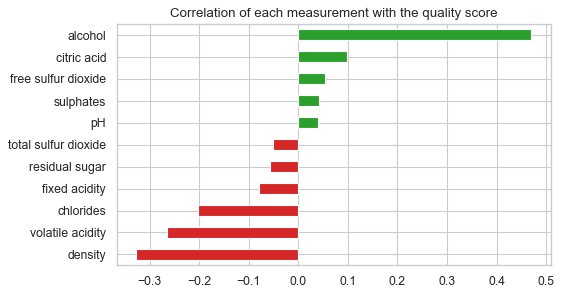

In [7]:
correlations = df.drop(columns="type").corr()["quality"].drop("quality").sort_values()
plt.figure(figsize=(7, 4))
correlations.plot.barh(color=["tab:red" if c < 0 else "tab:green" for c in correlations])
plt.title("Correlation of each measurement with the quality score")
plt.show()

**What we see.** **Alcohol** stands out with a correlation of about **+0.45**: stronger wines tend to score higher. The strongest negative signals are **density** and **volatile acidity** (the acidity that gives a vinegar smell). Most other measurements have correlations near zero, which does not prove they are useless; it may mean their effect is curved, or different for red and white.

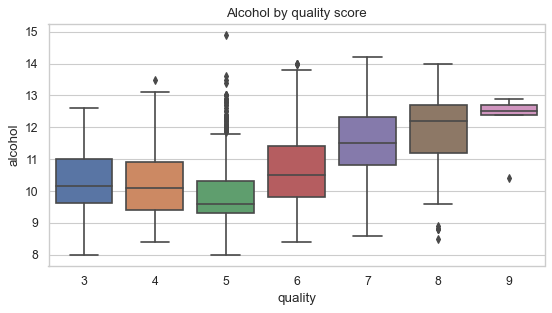

quality,3,4,5,6,7,8,9
mean alcohol %,10.22,10.22,9.87,10.65,11.51,11.91,12.18


In [8]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol by quality score")
plt.show()
df.groupby("quality")["alcohol"].mean().round(2).to_frame("mean alcohol %").T

**What we see.** From score 5 upwards, every step brings more alcohol: about **9.9%** at score 5, **11.5%** at 7 and over **12%** at 9. But the bottom of the scale does not follow: wines scored 3 and 4 have **more** alcohol than those scored 5. The relationship is not a straight line, and the low scores are so few (30 and 206 wines) that their averages are uncertain anyway.

Why would density be negative? Alcohol is lighter than water, so stronger wines are less dense. Density is largely **alcohol seen from another angle**, the redundancy we met in the house prices.

In [9]:
by_type = pd.DataFrame({t: g.drop(columns="type").corr()["quality"].drop("quality") for t, g in df.groupby("type")})
by_type.sort_values("red").round(2)

,red,white
volatile acidity,-0.40,-0.19
density,-0.18,-0.34
total sulfur dioxide,-0.18,-0.18
chlorides,-0.13,-0.22
pH,-0.06,0.12
free sulfur dioxide,-0.05,0.01
residual sugar,0.01,-0.12
fixed acidity,0.12,-0.12
citric acid,0.23,0.01
sulphates,0.25,0.05


**What we see.** Red and white wines agree on **alcohol** (positive for both) but differ elsewhere:
- **Volatile acidity** is the strongest negative signal for **red** wine, and much weaker for white.
- **Sulphates** help red wines and hardly matter for white.

A single correlation over both types would have mixed two different stories, the same warning as Simpson's paradox in the penguins. Whenever data combines groups, look at each group.

In [10]:
df.groupby("type")[["total sulfur dioxide", "residual sugar", "volatile acidity", "alcohol"]].mean().round(1)

,total sulfur dioxide,residual sugar,volatile acidity,alcohol
type,,,,
red,46.8,2.5,0.5,10.4
white,137.2,5.9,0.3,10.6


**What we see.** The two types are chemically very different: white wines have about **three times** the sulphur dioxide (a preservative) and much more residual sugar; red wines have more volatile acidity. A model that knows the `type` can learn separate rules; we keep it as a feature.

## 5. Predicting the score

### Formal setup
We treat the score as a **number** and measure the **mean absolute error**: on average, how many points is the prediction away from the tasters' score? We also round each prediction to the nearest whole score and count **exact hits**.

In [11]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

X = pd.get_dummies(df.drop(columns="quality"), drop_first=True)
y = df["quality"]
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = {"always the median score (6)": np.full(len(y), y.median())}
rows["linear regression"] = cross_val_predict(LinearRegression(), X, y, cv=cv)
rows["random forest"] = cross_val_predict(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), X, y, cv=cv)
pd.DataFrame({name: {"mean absolute error": mean_absolute_error(y, p), "exact score after rounding": (np.round(p) == y).mean()}
              for name, p in rows.items()}).T.round(3)

,mean absolute error,exact score after rounding
always the median score (6),0.643,0.437
linear regression,0.566,0.541
random forest,0.526,0.577


**What we see.** Always guessing 6 is wrong by **0.64** points on average. Linear regression improves this to **0.57**, a random forest to **0.53**, and the forest gets the exact score right for **58%** of wines. That is better than guessing, but far from the precision of a taster: chemistry captures part of taste, not all of it.

In [12]:
forest_pred = np.round(rows["random forest"]).astype(int)
pd.crosstab(y, forest_pred, rownames=["true score"], colnames=["predicted score"])

predicted score,4,5,6,7
true score,,,,
3,2,15,13,0
4,2,153,50,1
5,5,1097,634,16
6,0,487,1641,195
7,0,25,504,327
8,0,1,70,77
9,0,0,1,4


**What we see.** This table shows **where** the model fails. Read each row: the model **never** predicts a 3, an 8 or a 9. Of the 30 wines scored 3, it calls most of them 5 or 6; of the 148 wines scored 8, it calls **77** a 7 and 70 a 6. Predictions are squeezed towards the **middle** of the scale.

This is what any model does when most of the training examples sit in the middle and errors are measured by distance: when unsure, the safest guess is close to the average. It is a property of the data, not a bug in the forest.

### The cost of duplicates, measured

In [13]:
with_copies = pd.concat([red, white], ignore_index=True)
X_copies = pd.get_dummies(with_copies.drop(columns="quality"), drop_first=True)
leaky = cross_val_predict(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), X_copies, with_copies["quality"], cv=cv)
print("Random forest error WITH the duplicate rows:    ", round(mean_absolute_error(with_copies["quality"], leaky), 3))
print("Random forest error WITHOUT the duplicate rows: ", round(mean_absolute_error(y, rows["random forest"]), 3))

Random forest error WITH the duplicate rows:     0.431
Random forest error WITHOUT the duplicate rows:  0.526


**What we see.** With the copies left in, the same forest seems to have an error of **0.43** instead of **0.53**, an apparent improvement of almost 20% that is entirely **fake**: the model was being tested on wines it had already memorised. On a genuinely new wine it would do no better. Many published results on this dataset report the inflated number; checking for duplicates **before** splitting is what prevents it.

## 6. Can we at least find the good wines?

A wine merchant may not need the exact score, only the answer to *"is this wine good?"*. We call a wine **good** if it scored **7 or more**.

In [14]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

good = (y >= 7).astype(int)
print("Share of good wines:", round(good.mean(), 3))
scv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred_good = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), X, good, cv=scv)
print(f"Random forest: accuracy {accuracy_score(good, pred_good):.3f}, recall {recall_score(good, pred_good):.3f}, precision {precision_score(good, pred_good):.3f}")

Share of good wines: 0.19


Random forest: accuracy 0.845, recall 0.373, precision 0.665


**What we see.** Only **19%** of wines are good, so "never good" is already right 81% of the time. The forest reaches **84.5%** accuracy, but it finds only **37%** of the good wines (recall). When it does call a wine good, it is right **67%** of the time (precision).

So the honest answer for the merchant: the model's "good" label is a useful shortlist, two out of three are really good, but it overlooks most good wines. Lowering the threshold, as in Notebooks 04 and 05, would find more of them at the cost of more mistakes.

## 7. Answer to the question

*Can chemistry predict how good a wine tastes?*

1. **Partly.** Alcohol is the strongest single signal (stronger wines score higher, from score 5 upwards); volatile acidity lowers scores, especially for red wine; red and white wines follow partly different rules.
2. The best model misses the tasters' score by about **half a point** on average and gets the exact score for about 58% of wines.
3. Predictions are **squeezed towards 5 and 6**: the model never predicts the rare scores 3, 8 or 9.
4. It can shortlist good wines with about **two thirds precision**, but finds only about a third of them.
5. **18% of the rows were duplicates.** Leaving them in makes the model look 20% better than it is.

## 🚀 Going further (for experienced students)

### Keeping duplicates, without the leak: `GroupKFold`
Dropping duplicates is not the only fix. If the copies were real (two bottles of the same wine scored by different panels), we might want to keep them. The leak only happens when copies land on **both sides** of a split. **`GroupKFold`** gives every set of identical rows the same group number and guarantees that a whole group is either in training or in testing, never both.

In [15]:
from sklearn.model_selection import GroupKFold

orig = pd.concat([red, white], ignore_index=True)
groups = orig.groupby(list(orig.columns), sort=False).ngroup()
X_orig = pd.get_dummies(orig.drop(columns="quality"), drop_first=True)
grouped = cross_val_predict(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), X_orig, orig["quality"],
                            cv=GroupKFold(n_splits=5), groups=groups)
print("All 6,497 rows, copies kept together (GroupKFold):", round(mean_absolute_error(orig["quality"], grouped), 3))
print("Copies split at random (leaky):                   ", round(mean_absolute_error(with_copies["quality"], leaky), 3))

All 6,497 rows, copies kept together (GroupKFold): 0.526
Copies split at random (leaky):                    0.431


**What we see.** With all 6,497 rows kept but the copies held together, the error is **0.526**, exactly what we found after removing the duplicates, and far from the leaky **0.431**. The leak came from copies on both sides of the split, not from the copies themselves. `GroupKFold` is the general tool whenever rows belong together: several photos of one patient, several sales of one customer, several readings from one sensor.

## ⚠️ Common pitfalls

- **Stacking files without a source column.** Once combined, you can no longer tell red from white unless you recorded it.
- **Splitting data that contains duplicates.** Copies on both sides of the split leak the answer; remove them, or keep all copies of a row in the same fold.
- **Treating a score as a precise measurement.** A score of 6 is the median of a few human opinions; expect noise that no model can remove.
- **Judging a model by its average error alone.** Look at the confusion table: a model can be "accurate" and still never predict the rare classes that matter.
- **Mixing groups in one correlation.** Red and white wines need separate looks.

## ✏️ Exercises

### Exercise 1 (Red only)
Repeat the random forest regression of Section 5 on **red wines only**. Is the error larger or smaller than for all wines together? Which three features does the forest rely on most?

In [16]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
reds = df[df["type"] == "red"]
Xr, yr = reds.drop(columns=["quality", "type"]), reds["quality"]
forest = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
print("red-only error:", round(mean_absolute_error(yr, cross_val_predict(forest, Xr, yr, cv=cv)), 3))
print(pd.Series(forest.fit(Xr, yr).feature_importances_, index=Xr.columns).sort_values(ascending=False).head(3).round(3))
```

*The red-only model relies on alcohol, sulphates and volatile acidity, the three signals that the per-type correlations of Section 4 pointed to for red wine. Its error is of the same order as the combined model, with far fewer wines to learn from.*
</details>

### Exercise 2 (Scores as classes)
Train a `RandomForestClassifier` that predicts the score **as a class** (3, 4, ... 9) instead of a number. Compare its exact-score rate with the regression forest. Which approach makes the bigger mistakes when it is wrong?

In [17]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
as_class = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), X, y, cv=scv)
print("classifier: exact", round((as_class == y).mean(), 3), " mean absolute error", round(mean_absolute_error(y, as_class), 3))
print("regression: exact", round((forest_pred == y).mean(), 3), " mean absolute error", round(mean_absolute_error(y, forest_pred), 3))
```

*Here the two come out almost the same (about 58% exact and an error near 0.47 points for both), because almost all mistakes are between neighbouring scores anyway. In principle they differ: the classifier does not know that 5 is closer to 6 than to 9, so for it every wrong class is equally wrong, while a regression knows the order of the scores. With more spread-out scores, that difference starts to matter.*
</details>

### Exercise 3 (Where do the copies come from?)
Among the duplicate rows of the **original** two files, which quality scores are most common? Are duplicates spread evenly, or concentrated in some scores or one wine type?

In [18]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
orig = pd.concat([red, white], ignore_index=True)
dup = orig[orig.duplicated(keep=False)]
print(dup.groupby("type")["quality"].value_counts().unstack(0).fillna(0).astype(int))
```

*Duplicates appear in both types and mostly at scores 5 and 6, simply because most wines have those scores. Checking where duplicates sit is a quick way to see whether removing them could bias the data.*
</details>

## 🔑 Key takeaways

- When combining files, **record the source** of every row.
- **Duplicates** across a train/test split leak the answer; here they made a model look 20% better than it is.
- Human **scores** are narrow, noisy and crowded in the middle; models trained on them predict towards the average and miss the rare extremes.
- Look at the **confusion table**, not only the average error, to see which values a model can never produce.
- Correlations over **mixed groups** (red and white) can hide different rules for each.

---
**Next:** *Notebook 07: Bike Sharing*, where every row is an hour in time, and the patterns are daily, weekly and seasonal.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*